In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

apps_df = pd.read_csv('googleplaystore.csv')
reviews_df = pd.read_csv('googleplaystore_user_reviews.csv')

apps_df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [3]:
apps_df.shape
apps_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [4]:
apps_df.isnull().sum()

,0
App,0
Category,0
Rating,1474
Reviews,0
Size,0
Installs,0
Type,1
Price,0
Content Rating,1
Genres,0


In [5]:
print(apps_df['Installs'].unique()[:10])
print(apps_df['Price'].unique()[:10])
print(apps_df['Reviews'].dtype)

['10,000+' '500,000+' '5,000,000+' '50,000,000+' '100,000+' '50,000+'
 '1,000,000+' '10,000,000+' '5,000+' '100,000,000+']
['0' '$4.99' '$3.99' '$6.99' '$1.49' '$2.99' '$7.99' '$5.99' '$3.49'
 '$1.99']
object


In [6]:
# Clean Installs column: remove '+' and ',' then convert to number
apps_df['Installs'] = apps_df['Installs'].str.replace('+', '', regex=False)
apps_df['Installs'] = apps_df['Installs'].str.replace(',', '', regex=False)
apps_df['Installs'] = pd.to_numeric(apps_df['Installs'], errors='coerce')

# Clean Price column: remove '$' then convert to number
apps_df['Price'] = apps_df['Price'].str.replace('$', '', regex=False)
apps_df['Price'] = pd.to_numeric(apps_df['Price'], errors='coerce')

# Clean Reviews column: convert to number
apps_df['Reviews'] = pd.to_numeric(apps_df['Reviews'], errors='coerce')

print(apps_df[['Installs', 'Price', 'Reviews']].dtypes)

Installs    float64
Price       float64
Reviews     float64
dtype: object


In [7]:
apps_df[['Installs', 'Price', 'Reviews']].isnull().sum()

,0
Installs,1
Price,1
Reviews,1


In [8]:
apps_df[apps_df['Installs'].isnull()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,NaN,"1,000+",NaN,0,NaN,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [9]:
apps_df = apps_df.dropna(subset=['Installs', 'Price', 'Reviews'])
print(apps_df.shape)
print(apps_df[['Installs', 'Price', 'Reviews']].isnull().sum())

(10840, 13)
Installs    0
Price       0
Reviews     0
dtype: int64


## Data Cleaning

The Installs, Price, and Reviews columns were stored as text (e.g., "10,000+", "4.99 dollars") rather than numbers. Cleaned by removing special characters (plus sign, comma, dollar sign) and converting to numeric type using pd.to_numeric() with errors='coerce'.

This process revealed one corrupted row (index 10472) where column values were shifted due to a missing Category field (Rating showed an impossible value of 19.0 instead of a 0-5 scale). This single row was dropped, as it represented a data entry error affecting the entire record rather than a simple missing value.

In [10]:
apps_df.isnull().sum()

,0
App,0
Category,0
Rating,1474
Reviews,0
Size,0
Installs,0
Type,1
Price,0
Content Rating,0
Genres,0


In [14]:
apps_df['Rating'] = apps_df['Rating'].fillna(apps_df['Rating'].median())

In [15]:
apps_df = apps_df.dropna(subset=['Type', 'Content Rating', 'Current Ver', 'Android Ver'])
print(apps_df.shape)
print(apps_df.isnull().sum())

(10829, 13)
App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64


In [16]:
print(apps_df.duplicated().sum())
apps_df = apps_df.drop_duplicates()
print(apps_df.shape)

483
(10346, 13)


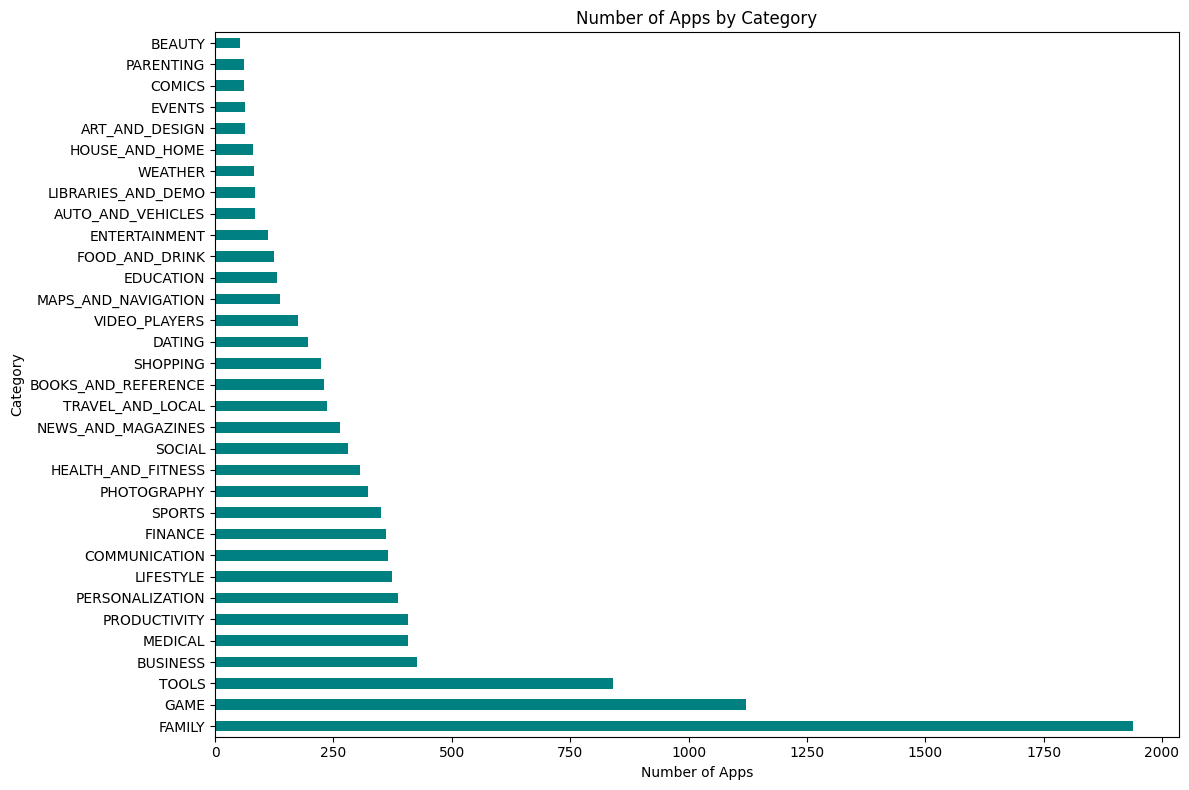

In [17]:
plt.figure(figsize=(12,8))
apps_df['Category'].value_counts().plot(kind='barh', color='teal')
plt.title('Number of Apps by Category')
plt.xlabel('Number of Apps')
plt.tight_layout()
plt.show()

## Category Analysis

The FAMILY, GAME, and TOOLS categories are by far the most saturated, each containing significantly more apps than any other category. This suggests heavy competition for new developers targeting these spaces. In contrast, categories like BEAUTY, PARENTING, and COMICS have relatively few apps, potentially representing less saturated niches worth exploring for new app launches.

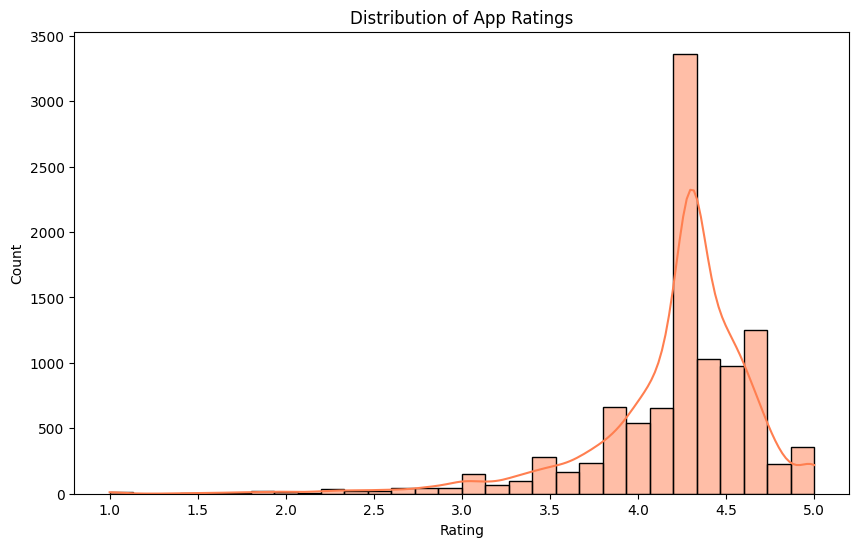

In [18]:
plt.figure(figsize=(10,6))
sns.histplot(apps_df['Rating'], bins=30, kde=True, color='coral')
plt.title('Distribution of App Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

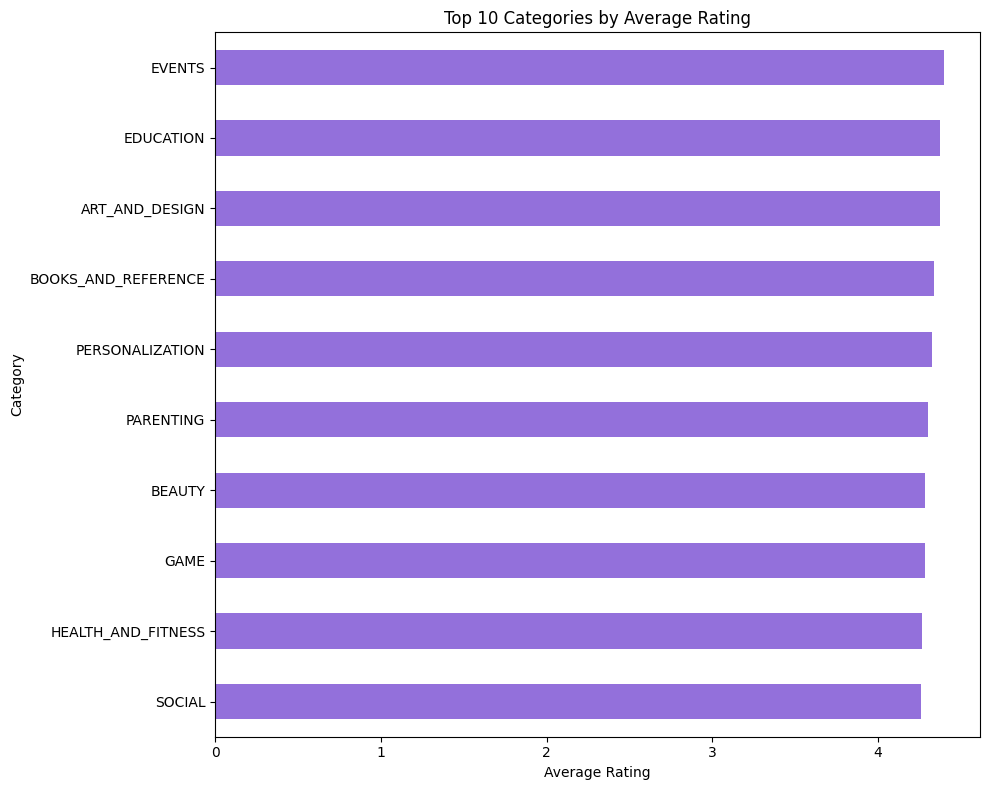

In [19]:
avg_rating = apps_df.groupby('Category')['Rating'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,8))
avg_rating.plot(kind='barh', color='mediumpurple')
plt.title('Top 10 Categories by Average Rating')
plt.xlabel('Average Rating')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Ratings Analysis

Events, Education, and Art and Design categories have the highest average user ratings, all above 4.3. Interestingly, this does not overlap much with the most saturated categories (Family, Game, Tools) from the earlier category analysis, suggesting that popularity (number of apps) and user satisfaction (average rating) are somewhat independent in this market.

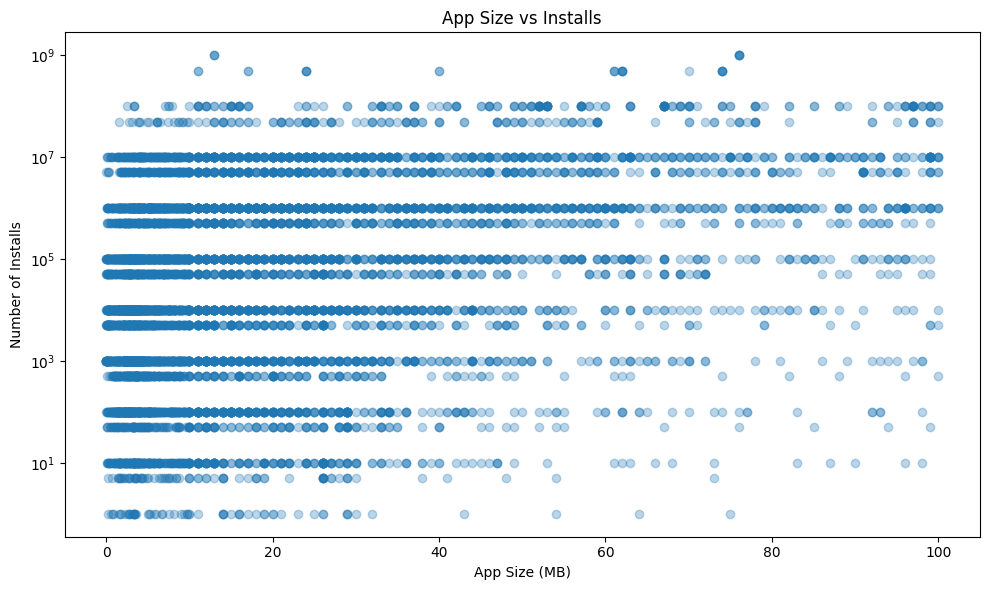

In [20]:
# Clean Size column first - remove 'M' and 'k', convert to numeric (MB)
def clean_size(size):
    if 'M' in str(size):
        return float(size.replace('M', ''))
    elif 'k' in str(size):
        return float(size.replace('k', '')) / 1024
    else:
        return np.nan

apps_df['Size_MB'] = apps_df['Size'].apply(clean_size)

plt.figure(figsize=(10,6))
plt.scatter(apps_df['Size_MB'], apps_df['Installs'], alpha=0.3)
plt.xlabel('App Size (MB)')
plt.ylabel('Number of Installs')
plt.title('App Size vs Installs')
plt.yscale('log')
plt.tight_layout()
plt.show()

## Size and Installs Analysis

The scatter plot of app size versus number of installs (log scale) shows no strong correlation between the two. Apps across all size ranges, from very small to 100+ MB, achieve both low and high install counts. This suggests that app size is not a major factor in an app's popularity, and other factors (category, marketing, quality, ratings) likely matter more than file size.

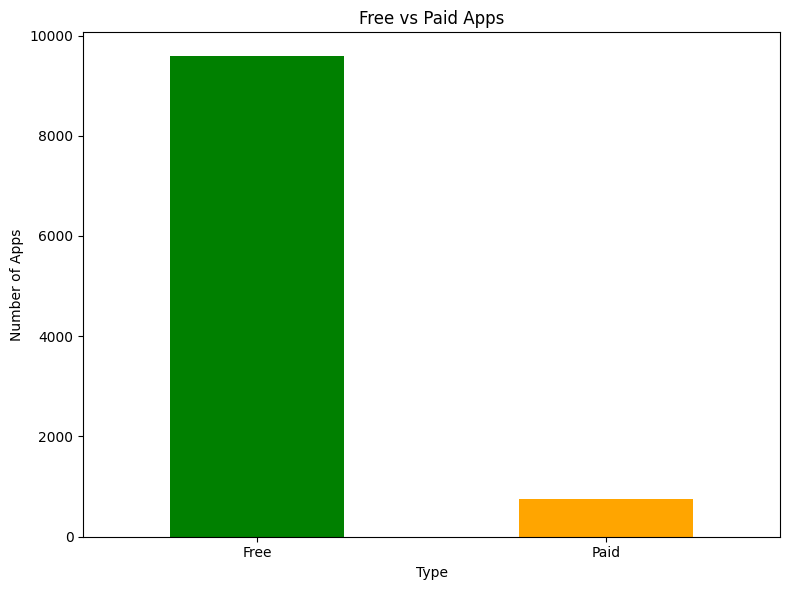

Type
Free    9584
Paid     762
Name: count, dtype: int64


In [21]:
type_counts = apps_df['Type'].value_counts()

plt.figure(figsize=(8,6))
type_counts.plot(kind='bar', color=['green', 'orange'])
plt.title('Free vs Paid Apps')
plt.xlabel('Type')
plt.ylabel('Number of Apps')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(type_counts)

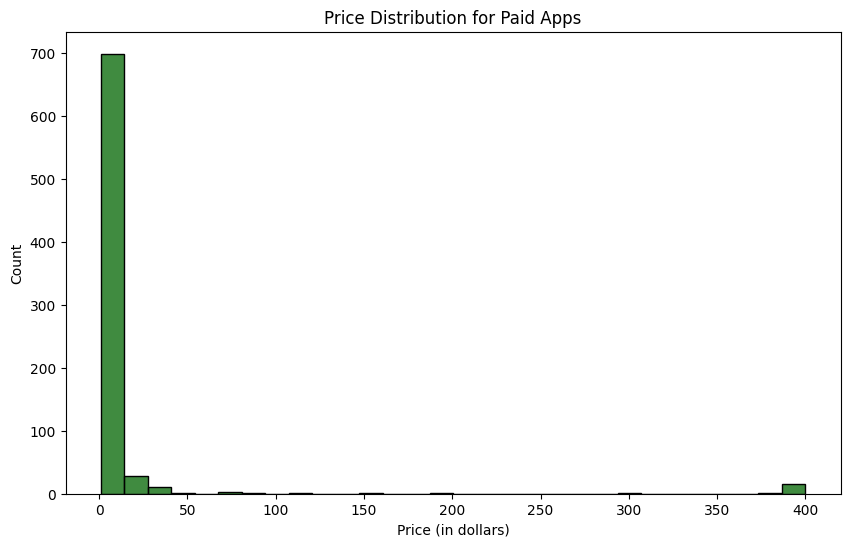

In [22]:
paid_apps = apps_df[apps_df['Type'] == 'Paid']

plt.figure(figsize=(10,6))
sns.histplot(paid_apps['Price'], bins=30, color='darkgreen')
plt.title('Price Distribution for Paid Apps')
plt.xlabel('Price (in dollars)')
plt.ylabel('Count')
plt.show()

## Pricing Analysis

The overwhelming majority of paid apps are priced under 10 dollars, with the distribution heavily right-skewed. A small number of extreme outliers reach up to 400 dollars, likely representing niche business tools or novelty apps rather than typical consumer purchases. This suggests that competitive app pricing in this market generally stays low, and apps priced significantly higher are rare exceptions.

In [23]:
reviews_df.head()
reviews_df['Sentiment'].value_counts()

,count
Sentiment,
Positive,23998
Negative,8271
Neutral,5163


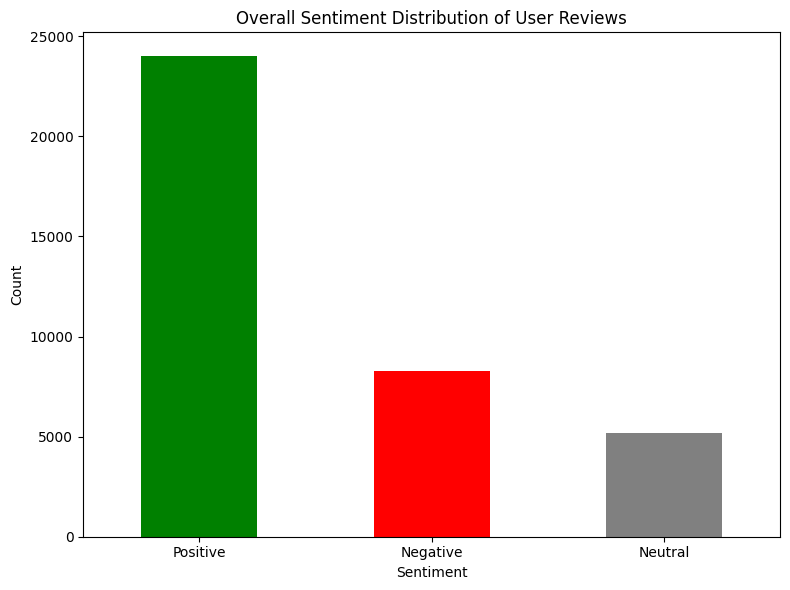

In [24]:
plt.figure(figsize=(8,6))
reviews_df['Sentiment'].value_counts().plot(kind='bar', color=['green', 'red', 'gray'])
plt.title('Overall Sentiment Distribution of User Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

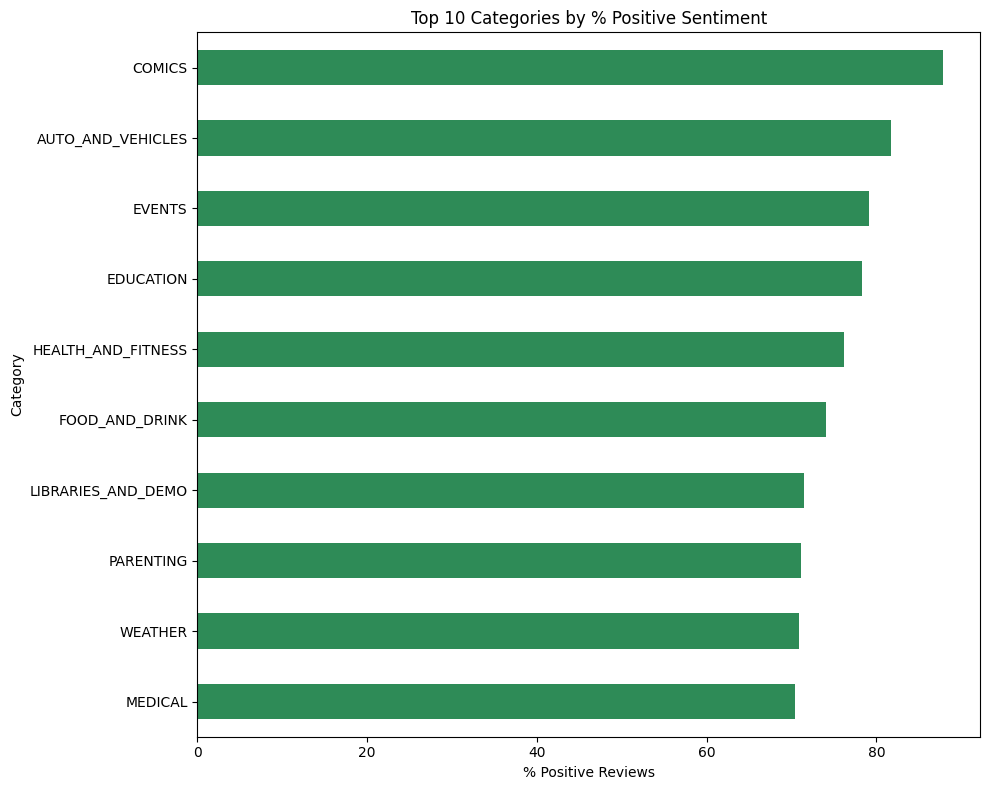

In [25]:
merged_df = pd.merge(reviews_df, apps_df[['App', 'Category']], on='App', how='inner')
merged_df.dropna(subset=['Sentiment'], inplace=True)

sentiment_by_category = merged_df.groupby('Category')['Sentiment'].apply(
    lambda x: (x == 'Positive').sum() / len(x) * 100
).sort_values(ascending=False).head(10)

plt.figure(figsize=(10,8))
sentiment_by_category.plot(kind='barh', color='seagreen')
plt.title('Top 10 Categories by % Positive Sentiment')
plt.xlabel('% Positive Reviews')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Sentiment Analysis by Category

Comics, Auto and Vehicles, and Events categories have the highest percentage of positive user reviews. Combined with the earlier ratings analysis, this reinforces that smaller, less saturated categories (like Comics and Events) tend to have more satisfied users, possibly because niche apps in these spaces face less competition and can focus on serving a dedicated audience well, rather than competing in a crowded market like Games or Tools.

## Conclusion and Insights for a Developer

Based on this analysis of the Google Play Store, three key insights for a developer planning to launch a new app:

1. Avoid oversaturated categories like Family, Game, and Tools unless offering a genuinely differentiated product, since competition is extremely high in these spaces.

2. Consider underexplored, high-satisfaction niches like Comics, Events, or Auto and Vehicles, which show both lower app counts and higher user sentiment, suggesting room for a well-executed app to stand out.

3. Price conservatively. The vast majority of successful paid apps are priced under 10 dollars; pricing significantly higher without strong differentiation and justification is a very unusual strategy in this market.